In [19]:

import nltk
from datasets import load_dataset
import gensim.downloader as api
import string
import torch
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

In [20]:
wv = api.load('word2vec-google-news-300')

In [21]:
# Standard deviation of each word's 300-dimensional vector
#This tells us we should use 0.1 to initialize our random vectors for embedding matrix
stds = np.std(wv.vectors, axis=1)

print(f"Number of words: {len(stds):,}")
print(f"Mean std:        {np.mean(stds):.6f}")
print(f"Median std:      {np.median(stds):.6f}")
print(f"Min std:         {np.min(stds):.6f}")
print(f"Max std:         {np.max(stds):.6f}")
print(f"Overall std:     {np.std(wv.vectors):.6f}")

print("\nPercentiles:")
for p in [5, 25, 50, 75, 95]:
    print(f"{p}th percentile: {np.percentile(stds, p):.6f}")

Number of words: 3,000,000
Mean std:        0.117574
Median std:      0.100067
Min std:         0.000874
Max std:         1.216954
Overall std:     0.133150

Percentiles:
5th percentile: 0.048978
25th percentile: 0.071150
50th percentile: 0.100067
75th percentile: 0.152243
95th percentile: 0.237577


Load Dataset

In [22]:
train = load_dataset("amarfurt/art-nlp-hs26", split="train")
valid = load_dataset("amarfurt/art-nlp-hs26", split="validation")
test = load_dataset("amarfurt/art-nlp-hs26", split="test")

In [23]:
for batch in train.iter(batch_size=1):
    o1 = batch["observation_1"]
    o2 = batch["observation_2"]
    h1 = batch["hypothesis_1"]
    h2 = batch["hypothesis_2"]
    label = batch["label"]
    print(batch)
    print(o1)
    print(o2)
    print(h1)
    print(h2)
    print(label)
    break

#okay so we get an entire batch of sentences like this

{'observation_1': ['A baby panda was lost in the woods.'], 'observation_2': ['He was reunited with his parents, who also lived at the zoo.'], 'hypothesis_1': ['He was never lost.'], 'hypothesis_2': ['All the people from the zoo looked for him.'], 'label': [2]}
['A baby panda was lost in the woods.']
['He was reunited with his parents, who also lived at the zoo.']
['He was never lost.']
['All the people from the zoo looked for him.']
[2]


In [24]:
def preprocess_lowercase(text):
    tokens = nltk.word_tokenize(text.lower())
    tokens = [token for token in tokens]
    return tokens

def preprocess_no_lower(text):
    tokens = nltk.word_tokenize(text)
    tokens = [token for token in tokens]
    return tokens

In [25]:
processed_words = []

for i in range(len(train)):
    
    processed = {
        "observation_1": preprocess_lowercase(train[i]["observation_1"]),
        "observation_2": preprocess_lowercase(train[i]["observation_2"]),
        "hypothesis_1": preprocess_lowercase(train[i]["hypothesis_1"]),
        "hypothesis_2": preprocess_lowercase(train[i]["hypothesis_2"]),
        "label": train[i]["label"]
    }
    
    processed_words.append(processed)

print(len(processed_words))
print(processed_words[:5])

16801
[{'observation_1': ['a', 'baby', 'panda', 'was', 'lost', 'in', 'the', 'woods', '.'], 'observation_2': ['he', 'was', 'reunited', 'with', 'his', 'parents', ',', 'who', 'also', 'lived', 'at', 'the', 'zoo', '.'], 'hypothesis_1': ['he', 'was', 'never', 'lost', '.'], 'hypothesis_2': ['all', 'the', 'people', 'from', 'the', 'zoo', 'looked', 'for', 'him', '.'], 'label': 2}, {'observation_1': ['a', 'bank', 'teller', 'told', 'me', 'to', 'rob', 'the', 'bank', 'where', 'she', 'worked', '.'], 'observation_2': ['we', 'split', 'the', 'money', 'equally', '.'], 'hypothesis_1': ['the', 'mountain', 'told', 'me', 'when', 'no', 'one', 'would', 'be', 'there', '.'], 'hypothesis_2': ['the', 'teller', 'told', 'me', 'when', 'no', 'one', 'would', 'be', 'there', '.'], 'label': 2}, {'observation_1': ['a', 'bee', 'was', 'buzzing', 'around', 'my', 'head', '.'], 'observation_2': ['i', 'did', "n't", 'bother', 'to', 'explain', 'the', 'situation', '.'], 'hypothesis_1': ['it', 'was', 'because', 'of', 'the', 'honey',

In [26]:
print(wv.vector_size)
print(len(wv.index_to_key))

for index, word in enumerate(wv.index_to_key[:10]):
    print(index, word) #This lets us see that it has upper and lowercase input data so we should use the same in preprocessing
    
for index, word in enumerate(wv.index_to_key[-5:]):
    print(index + len(wv.index_to_key) - 5, word) 
    
print(f"known word: {"king" in wv}")
print(f"UNK: {"ndisud" in wv}")

300
3000000
0 </s>
1 in
2 for
3 that
4 is
5 on
6 ##
7 The
8 with
9 said
2999995 RAFFAELE
2999996 Bim_Skala_Bim
2999997 Mezze_Cafe
2999998 pulverizes_boulders
2999999 snowcapped_Caucasus
known word: True
UNK: False


EXCLUDE lowercase

In [27]:
tokenized_words_no_lower = []

for i in range(len(train)):
    
    processed = {
        "observation_1": preprocess_no_lower(train[i]["observation_1"]),
        "observation_2": preprocess_no_lower(train[i]["observation_2"]),
        "hypothesis_1": preprocess_no_lower(train[i]["hypothesis_1"]),
        "hypothesis_2": preprocess_no_lower(train[i]["hypothesis_2"]),
        "label": train[i]["label"]
    }
    
    tokenized_words_no_lower.append(processed)
    
print(len(tokenized_words_no_lower))
for i in range(5):
    for key, sentence in tokenized_words_no_lower[i].items():
        print(f"{key}: {sentence}")

16801
observation_1: ['A', 'baby', 'panda', 'was', 'lost', 'in', 'the', 'woods', '.']
observation_2: ['He', 'was', 'reunited', 'with', 'his', 'parents', ',', 'who', 'also', 'lived', 'at', 'the', 'zoo', '.']
hypothesis_1: ['He', 'was', 'never', 'lost', '.']
hypothesis_2: ['All', 'the', 'people', 'from', 'the', 'zoo', 'looked', 'for', 'him', '.']
label: 2
observation_1: ['A', 'bank', 'teller', 'told', 'me', 'to', 'rob', 'the', 'bank', 'where', 'she', 'worked', '.']
observation_2: ['We', 'split', 'the', 'money', 'equally', '.']
hypothesis_1: ['The', 'mountain', 'told', 'me', 'when', 'no', 'one', 'would', 'be', 'there', '.']
hypothesis_2: ['The', 'teller', 'told', 'me', 'when', 'no', 'one', 'would', 'be', 'there', '.']
label: 2
observation_1: ['A', 'bee', 'was', 'buzzing', 'around', 'my', 'head', '.']
observation_2: ['I', 'did', "n't", 'bother', 'to', 'explain', 'the', 'situation', '.']
hypothesis_1: ['It', 'was', 'because', 'of', 'the', 'honey', 'in', 'my', 'hair', '.']
hypothesis_2: ['It

INCLUDE LOWERCASE

In [28]:
tokenized_words_lower = []

for i in range(len(train)):
    
    processed = {
        "observation_1": preprocess_lowercase(train[i]["observation_1"]),
        "observation_2": preprocess_lowercase(train[i]["observation_2"]),
        "hypothesis_1": preprocess_lowercase(train[i]["hypothesis_1"]),
        "hypothesis_2": preprocess_lowercase(train[i]["hypothesis_2"]),
        "label": train[i]["label"]
    }
    
    tokenized_words_lower.append(processed)

print(len(tokenized_words_lower))
for i in range(5):
    for key, sentence in tokenized_words_lower[i].items():
        print(f"{key}: {sentence}")

16801
observation_1: ['a', 'baby', 'panda', 'was', 'lost', 'in', 'the', 'woods', '.']
observation_2: ['he', 'was', 'reunited', 'with', 'his', 'parents', ',', 'who', 'also', 'lived', 'at', 'the', 'zoo', '.']
hypothesis_1: ['he', 'was', 'never', 'lost', '.']
hypothesis_2: ['all', 'the', 'people', 'from', 'the', 'zoo', 'looked', 'for', 'him', '.']
label: 2
observation_1: ['a', 'bank', 'teller', 'told', 'me', 'to', 'rob', 'the', 'bank', 'where', 'she', 'worked', '.']
observation_2: ['we', 'split', 'the', 'money', 'equally', '.']
hypothesis_1: ['the', 'mountain', 'told', 'me', 'when', 'no', 'one', 'would', 'be', 'there', '.']
hypothesis_2: ['the', 'teller', 'told', 'me', 'when', 'no', 'one', 'would', 'be', 'there', '.']
label: 2
observation_1: ['a', 'bee', 'was', 'buzzing', 'around', 'my', 'head', '.']
observation_2: ['i', 'did', "n't", 'bother', 'to', 'explain', 'the', 'situation', '.']
hypothesis_1: ['it', 'was', 'because', 'of', 'the', 'honey', 'in', 'my', 'hair', '.']
hypothesis_2: ['it

Count all the UNKs

In [29]:
def count_unk(dataset):
    unk_count = 0
    total_tokens = 0

    for sample in dataset:
        for key in ["observation_1", "observation_2",
                    "hypothesis_1", "hypothesis_2"]:
            for word in sample[key]:
                total_tokens += 1
                if word not in wv:
                    unk_count += 1

    return unk_count, unk_count / total_tokens * 100

for name, dataset in [
    ("No lowercase", tokenized_words_no_lower),
    ("Lowercase", tokenized_words_lower)
]:
    count, percentage = count_unk(dataset)
    print(f"{name}: {count} UNKs ({percentage:.2f}%)")

No lowercase: 141954 UNKs (21.66%)
Lowercase: 146674 UNKs (22.38%)


In [30]:
def remove_punctuation(tokens):
    return [
        token for token in tokens
        if token not in string.punctuation
    ]

def preprocess_without_punctuation(dataset):
    processed_dataset = []

    for sample in dataset:
        processed = {
            key: remove_punctuation(sample[key])
            for key in [
                "observation_1", "observation_2",
                "hypothesis_1", "hypothesis_2"
            ]
        }
        processed["label"] = sample["label"]
        processed_dataset.append(processed)

    return processed_dataset


# Apply preprocessing
no_lower_no_punct = preprocess_without_punctuation(tokenized_words_no_lower)
lower_no_punct = preprocess_without_punctuation(tokenized_words_lower)


# Compare UNK counts
for name, dataset in [
    ("No lowercase, punctuation removed", no_lower_no_punct),
    ("Lowercase, punctuation removed", lower_no_punct)
]:
    count, percentage = count_unk(dataset)
    print(f"{name}: {count} UNKs ({percentage:.2f}%)")

No lowercase, punctuation removed: 68442 UNKs (11.76%)
Lowercase, punctuation removed: 73162 UNKs (12.57%)


In [31]:
def most_common_unks(dataset, top_n=20):
    unknowns = Counter()

    for sample in dataset:
        for key in ["observation_1", "observation_2",
                    "hypothesis_1", "hypothesis_2"]:
            for word in sample[key]:
                if word not in wv:
                    unknowns[word] += 1

    return unknowns.most_common(top_n)

most_common_unks(no_lower_no_punct)

[('to', 23004),
 ('a', 19733),
 ('and', 13074),
 ('of', 5694),
 ("'s", 4798),
 ('``', 102),
 ('10', 63),
 ('20', 61),
 ('didnt', 53),
 ('100', 42),
 ('cancelled', 42),
 ("''", 37),
 ('50', 36),
 ('30', 34),
 ('’', 32),
 ('co-worker', 23),
 ('15', 22),
 ('12', 18),
 ('16', 16),
 ('18', 14)]

In [32]:
print("to" in wv)
print("a" in wv)
print("To" in wv)
print("A" in wv)

False
False
True
True


In [33]:
# Normalize tokens using Word2Vec vocabulary
def normalize_token(word):
    if word in wv:
        return word
    if word.lower() in wv:
        return word.lower()
    if word.capitalize() in wv:
        return word.capitalize()
    return word


def normalize_dataset(dataset):
    processed_dataset = []

    for sample in dataset:
        processed = sample.copy()

        for key in ["observation_1", "observation_2",
                    "hypothesis_1", "hypothesis_2"]:
            processed[key] = [
                normalize_token(word) for word in sample[key]
            ]

        processed_dataset.append(processed)

    return processed_dataset


# Apply normalization to dataset without punctuation
normalized_dataset = normalize_dataset(no_lower_no_punct)


# Compare UNK counts
for name, dataset in [
    ("No lowercase, no punctuation", no_lower_no_punct),
    ("Case-normalized, no punctuation", normalized_dataset)
]:
    count, percentage = count_unk(dataset)
    print(f"{name}: {count} UNKs ({percentage:.2f}%)")


# Show remaining unknown words
print("\nMost common remaining UNKs:")
print(most_common_unks(normalized_dataset))

No lowercase, no punctuation: 68442 UNKs (11.76%)
Case-normalized, no punctuation: 6738 UNKs (1.16%)

Most common remaining UNKs:
[("'s", 4798), ('``', 102), ('10', 63), ('20', 61), ('didnt', 53), ('100', 42), ("''", 37), ('50', 36), ('30', 34), ('’', 32), ('co-worker', 23), ('15', 22), ('12', 18), ('16', 16), ('18', 14), ('..', 14), ('200', 11), ('25', 10), ('21', 10), ('co-workers', 10)]


In [34]:
def merge_possessives(tokens):
    merged = []

    for token in tokens:
        if token == "'s" and merged:
            merged[-1] += token
        else:
            merged.append(token)

    return merged


text_fields = [
    "observation_1",
    "observation_2",
    "hypothesis_1",
    "hypothesis_2"
]

normalized_dataset = [
    {
        key: merge_possessives(value) if key in text_fields else value
        for key, value in example.items()
    }
    for example in normalized_dataset
]

print(normalized_dataset[0])

count, percentage = count_unk(normalized_dataset)
print(f"UNKs: {count} ({percentage:.2f}%)")

print("\nMost common remaining UNKs:")
print(most_common_unks(normalized_dataset))

{'observation_1': ['A', 'baby', 'panda', 'was', 'lost', 'in', 'the', 'woods'], 'observation_2': ['He', 'was', 'reunited', 'with', 'his', 'parents', 'who', 'also', 'lived', 'at', 'the', 'zoo'], 'hypothesis_1': ['He', 'was', 'never', 'lost'], 'hypothesis_2': ['All', 'the', 'people', 'from', 'the', 'zoo', 'looked', 'for', 'him'], 'label': 2}
UNKs: 6221 (1.08%)

Most common remaining UNKs:
[("Gina's", 192), ('``', 102), ("Year's", 88), ("Amy's", 85), ("friend's", 85), ("Bob's", 68), ('10', 63), ('20', 61), ("Tim's", 56), ("Tom's", 54), ('didnt', 53), ("Mary's", 50), ("Jim's", 49), ("Sam's", 47), ("neighbor's", 43), ("Dan's", 42), ('100', 42), ("Lucy's", 42), ("Bill's", 40), ("Jane's", 39)]


Original casing
  All tokens: 141,954 UNKs (21.66%)
  Without punctuation: 68,281 UNKs (11.74%)
Lowercase
  All tokens: 146,674 UNKs (22.38%)
  Without punctuation: 73,001 UNKs (12.55%)
Vocabulary-aware casing
  All tokens: 80,250 UNKs (12.24%)
  Without punctuation: 6,577 UNKs (1.13%)


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


Vocabulary-aware casing + possessive merging
  All tokens: 79,733 UNKs (12.25%)
  Without punctuation: 6,060 UNKs (1.05%)


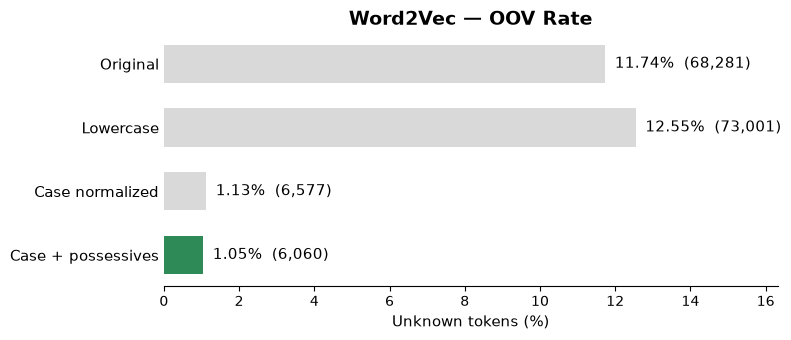

In [35]:
import matplotlib.pyplot as plt
import string

# -------- helper functions --------

def is_punctuation_token(token):
    return all(ch in string.punctuation for ch in token)

def count_unk_all_tokens(dataset):
    unk_count = 0
    total_count = 0

    for sample in dataset:
        for key in text_fields:
            for token in sample[key]:
                total_count += 1
                if token not in wv:
                    unk_count += 1

    return unk_count, (unk_count / total_count * 100) if total_count > 0 else 0

def count_unk_without_punctuation(dataset):
    unk_count = 0
    total_count = 0

    for sample in dataset:
        for key in text_fields:
            for token in sample[key]:
                if is_punctuation_token(token):
                    continue

                total_count += 1
                if token not in wv:
                    unk_count += 1

    return unk_count, (unk_count / total_count * 100) if total_count > 0 else 0

# -------- build datasets --------

original = tokenized_words_no_lower
lowercase = tokenized_words_lower
case_normalized = normalize_dataset(original)

case_normalized_merged = [
    {
        key: merge_possessives(value) if key in text_fields else value
        for key, value in sample.items()
    }
    for sample in case_normalized
]

experiments = {
    "Original casing": original,
    "Lowercase": lowercase,
    "Vocabulary-aware casing": case_normalized,
    "Vocabulary-aware casing + possessive merging": case_normalized_merged
}

# -------- collect metrics --------

names = []
all_counts = []
all_rates = []
word_counts = []
word_rates = []

for name, dataset in experiments.items():
    all_count, all_rate = count_unk_all_tokens(dataset)
    word_count, word_rate = count_unk_without_punctuation(dataset)

    names.append(name)
    all_counts.append(all_count)
    all_rates.append(all_rate)
    word_counts.append(word_count)
    word_rates.append(word_rate)

    print(f"{name}")
    print(f"  All tokens: {all_count:,} UNKs ({all_rate:.2f}%)")
    print(f"  Without punctuation: {word_count:,} UNKs ({word_rate:.2f}%)")

# -------- plot --------
# Main bar = word-only OOV rate (without punctuation)
# Annotation also shows overall OOV including punctuation
labels = [
    "Original",
    "Lowercase",
    "Case normalized",
    "Case + possessives"
]

# Automatically highlight the lowest OOV rate
best_idx = word_rates.index(min(word_rates))
colors = [
    "#2E8B57" if i == best_idx else "#D9D9D9"
    for i in range(len(word_rates))
]

fig, ax = plt.subplots(figsize=(8, 3.5))

bars = ax.barh(labels, word_rates, color=colors, height=0.6)

# Show percentage and absolute count
for bar, rate, count in zip(bars, word_rates, word_counts):
    ax.text(
        bar.get_width() + max(word_rates) * 0.02,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.2f}%  ({count:,})",
        va="center",
        fontsize=11,
        fontweight="medium"
    )

ax.invert_yaxis()
ax.set_xlim(0, max(word_rates) * 1.3)

ax.set_xlabel("Unknown tokens (%)", fontsize=11)
ax.set_title("Word2Vec — OOV Rate", fontsize=14, fontweight="bold")

ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=11)
ax.tick_params(axis="x", labelsize=10)

plt.tight_layout()

plt.savefig(
    "preprocessing_comparison.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()

In [36]:
import torch
import json
from pathlib import Path

DATA_DIR = Path("../data/processed")

KEYS = [
    "observation_1",
    "observation_2",
    "hypothesis_1",
    "hypothesis_2"
]

def get_unk_stats(data_dir=DATA_DIR):
    with open(data_dir / "vocab.json", encoding="utf-8") as f:
        vocab = json.load(f)

    unk_id = vocab["<UNK>"]
    results = {}

    for split in ["train", "valid", "test"]:
        samples = torch.load(
            data_dir / f"{split}.pt",
            weights_only=True
        )

        total = sum(
            len(sample[key])
            for sample in samples
            for key in KEYS
        )

        unknown = sum(
            token == unk_id
            for sample in samples
            for key in KEYS
            for token in sample[key]
        )

        results[split] = {
            "unknown": unknown,
            "total": total,
            "rate": 100 * unknown / total if total else 0
        }

    return results


stats = get_unk_stats()

for split, result in stats.items():
    print(
        f"{split}: {result['unknown']:,} / "
        f"{result['total']:,} tokens "
        f"({result['rate']:.2f}%)"
    )

train: 0 / 650,679 tokens (0.00%)
valid: 734 / 39,205 tokens (1.87%)
test: 1,125 / 59,983 tokens (1.88%)


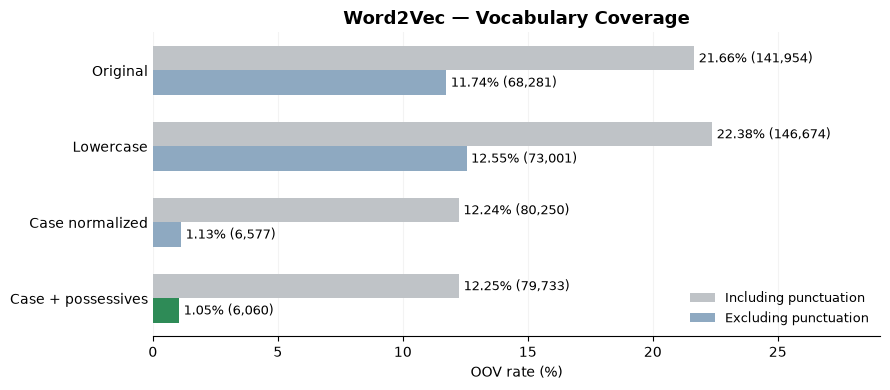

In [37]:
labels = [
    "Original",
    "Lowercase",
    "Case normalized",
    "Case + possessives"
]

y = np.arange(len(labels))
height = 0.32

fig, ax = plt.subplots(figsize=(9, 4))

# One bar for all tokens, one excluding punctuation
bars_all = ax.barh(
    y - height / 2,
    all_rates,
    height,
    color="#BFC3C7",
    label="Including punctuation"
)

bars_words = ax.barh(
    y + height / 2,
    word_rates,
    height,
    color=["#8EA9C1"] * 3 + ["#2E8B57"],
    label="Excluding punctuation"
)

# Percentage + absolute OOV count
for bars, rates, counts in [
    (bars_all, all_rates, all_counts),
    (bars_words, word_rates, word_counts)
]:
    for bar, rate, count in zip(bars, rates, counts):
        ax.text(
            bar.get_width() + 0.18,
            bar.get_y() + bar.get_height() / 2,
            f"{rate:.2f}% ({count:,})",
            va="center",
            fontsize=9
        )

ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xlim(0, max(all_rates + word_rates) * 1.3)

ax.set_xlabel("OOV rate (%)", fontsize=10)
ax.set_title("Word2Vec — Vocabulary Coverage", fontsize=13, weight="bold")

ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=9
)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "preprocessing_comparison.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()
